# Session 14 lecture: Dashboards and storytelling

<p class="lead">
A correct analysis that nobody understands changes nothing. This lecture turns analysis into communication: knowing your audience and their decision, writing one big idea, shaping a story, removing clutter from charts, laying out a dashboard a manager can read in a minute, and writing a one-page brief for executives.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/14_dashboards_storytelling_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 13 lecture](13_hr_workforce_lecture.md). Write short answers; we discuss them together.

1. A team opens a month with 120 people, hires 8 and has 5 exits. What is its closing headcount? Name the two checks that prove a monthly bridge is correct.
2. Why is annual turnover calculated on the **average** headcount rather than today's headcount? For a team that **shrank** during the year, does today's headcount make turnover look higher or lower?
3. An employee's last working day is 31 May. What exit date does the course's contract record, and why does that one day matter?
4. A role opened 90 days ago is still open. Why must it not be recorded as 0 days to fill, or dropped? What do you report instead?
5. An employee moves from one department to another. What happens to the company's hires and exits?
6. Why would you suppress a table cell that counts fewer than five leavers?

---

## What you will be able to explain

1. The difference between **exploratory** and **explanatory** analysis.
2. Why every presentation starts from an **audience** and a **decision**.
3. How to write a **big idea**: one sentence with a point of view and what is at stake.
4. How **situation → complication → resolution** turns findings into a story.
5. Why a **message title** beats a descriptive title.
6. What the **Challenger** O-ring data show when you include, or leave out, the flights with no damage.
7. How to **declutter** a default chart: data-ink, sorting, direct labels, one highlight colour and honest axes.
8. The design principles of a **dashboard**: layout, number of views, consistent colours, scope note, annotation and accessibility.
9. How to write a **one-page brief** for executives.

This lecture builds on [Storytelling with data](../foundations/storytelling.md) and [Designing clear visuals](../foundations/visual-design.md), and on the dashboard you built in the [Session 7 lab](07_trends_and_growth_lab.md). In the **Lab** you declutter a chart, rewrite titles, build a decision dashboard for one case, write an executive brief and repair a misleading dashboard.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cell first, then the cell after it, which loads the retail orders.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
import numpy as np
from matplotlib.ticker import StrMethodFormatter

THOUSANDS = StrMethodFormatter("{x:,.0f}")             # axis ticks like 20,000
GREY, BLUE, ORANGE = "#b8b6b0", "#2a78d6", "#eb6834"   # context, focus, alert

df = load_orders()
df["year"] = df["order_date"].dt.year
print("Order lines:", len(df), "| orders:", df["order_id"].nunique(),
      "| first order:", df["order_date"].min().date(), "| last order:", df["order_date"].max().date())

Order lines: 6815 | orders: 3388 | first order: 2023-01-03 | last order: 2025-12-31


---

## Part 1: Exploratory versus explanatory

Every analysis has two phases, and they need different charts.

| | Exploratory | Explanatory |
|---|---|---|
| **Purpose** | Find out what is in the data | Tell someone what you found and what to do |
| **Audience** | You (and your team) | A decision-maker |
| **Number of charts** | Many, quick, rough | As few as possible |
| **Titles** | Describe what is plotted | State the message |
| **Style** | Defaults are fine | Clean, highlighted, annotated, with a scope note |

In Sessions 2–13 you made dozens of exploratory charts. Most of them should **never** reach a manager. The skill in this session is choosing the few that matter and redrawing them so the message is impossible to miss.

### Audience and the decision

Before drawing anything, answer three questions:

1. **Who** is the audience, and what do they already know?
2. **What decision** do they face, and by when?
3. **What do you want them to do** or believe after seeing your work?

| Audience | What they need | What to leave out |
|---|---|---|
| Executive | The recommendation, two or three numbers, the main risk | Method details, every breakdown |
| Manager of one area | Their area against the rest, the trend, what to check next | Other areas' detail |
| Analyst colleague | Definitions, data checks, code | Nothing; they need the working |

The same finding can need three different presentations.

> **Check your understanding 1**
>
> In the Session 13 lab you compared turnover across departments. Name one chart you would show the **HR director** and one you would show only to an **analyst colleague**. Why the difference?

---

## Part 2: The big idea, the story and the title

### The big idea

Before building any chart, write your main message as **one sentence** that:

- states your **point of view** (what you think should happen),
- says **what is at stake** (why it matters now),
- is written for **your audience**.

> *Example:* "Returns in the West are far more common than anywhere else, so before we expand there next year we should find out why, starting with the products returned most often."

If you cannot write the sentence, you are not ready to build the presentation. Keep analysing.

### Situation, complication, resolution

A short business story has three parts:

| Part | Question it answers | Example (retail) |
|---|---|---|
| **Situation** | What is true and agreed? | Sales grew in every segment last year |
| **Complication** | What problem or tension does the data reveal? | One region's orders appear on the returns list far more often than the others' |
| **Resolution** | What should we do? | Investigate that region's returns before expanding there, and measure the share monthly |

The situation is short, because the audience usually knows it. The complication is the reason they are listening. The resolution is your recommendation.

### Message titles

A **descriptive title** says what is plotted. A **message title** says what the reader should notice.

| Descriptive title | Message title |
|---|---|
| Monthly Sales, 2023–2025 | Sales rise every autumn and dip every January |
| Profit by sub-category | A few sub-categories lose money, led by Tables |
| Share of orders on the returns list by region | West orders are on the returns list far more often than other regions' |

A message title must be **true for the data shown**, and specific enough to check. If you redraw the chart for different data, re-check the title.

> **Predict, then reveal**
>
> The cell below draws the same numbers twice: once as a default exploratory chart and once as an explanatory chart. Before you run it, list three things you expect to change.

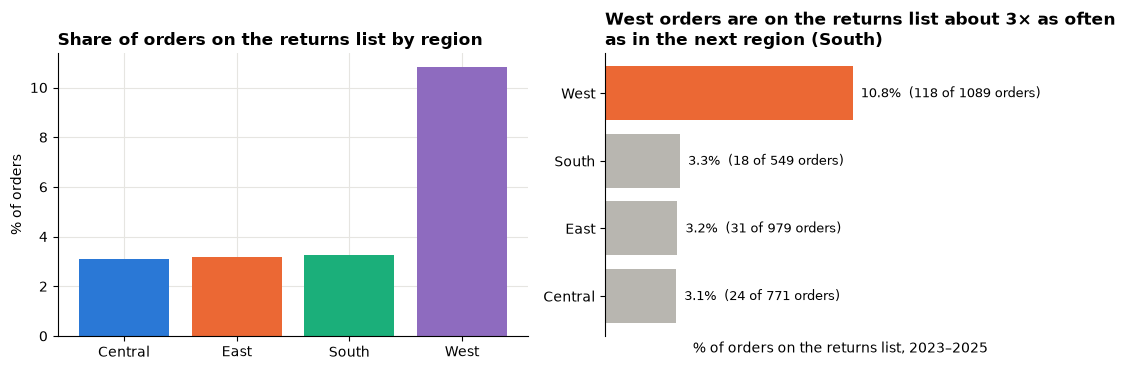

In [3]:
orders_by_region = df.groupby("region")["order_id"].nunique()
listed_by_region = df[df["returned_order_flag"] == 1].groupby("region")["order_id"].nunique()
share = (listed_by_region / orders_by_region).sort_values()
top, runner_up = share.index[-1], share.index[-2]
times = share.iloc[-1] / share.iloc[-2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

# Exploratory: defaults, alphabetical order, one colour per bar, descriptive title
alphabetical = share.sort_index()
ax1.bar(alphabetical.index, alphabetical * 100, color=["#2a78d6", "#eb6834", "#1baf7a", "#8e6bbf"])
ax1.set_title("Share of orders on the returns list by region")
ax1.set_ylabel("% of orders")

# Explanatory: sorted, grey context, one highlight, direct labels, message title
ax2.barh(share.index, share * 100, color=[ORANGE if r == top else GREY for r in share.index])
for i, (region, value) in enumerate(share.items()):
    ax2.text(value * 100, i, f"  {value:.1%}  ({listed_by_region[region]} of {orders_by_region[region]} orders)",
             va="center", fontsize=9)
ax2.set_title(f"{top} orders are on the returns list about {times:.0f}× as often\nas in the next region ({runner_up})")
ax2.set_xlabel("% of orders on the returns list, 2023–2025")
ax2.set_xlim(0, share.max() * 100 * 1.9)
ax2.set_xticks([])
ax2.grid(False)
ax2.spines["bottom"].set_visible(False)

fig.tight_layout()
plt.show()

Compare the two charts above:

1. The **order** changed: alphabetical on the left, sorted on the right, so the ranking is instant.
2. The **colours** changed: four colours that mean nothing on the left; grey for context and one orange bar on the right.
3. The **numbers** moved onto the bars, with the counts behind each share, so the reader does not need the axis.
4. The **title** changed from a label to a claim the reader can check against the bars.

Remember from Session 7: the returns list says only **which orders** appear on it. It has no dates, amounts or reasons. The right-hand title states a fact about the list, not a cause.

> **Check your understanding 2**
>
> Write a situation, complication and resolution, one sentence each, for the right-hand chart above. Which of the three sentences needs evidence that this chart does not contain?

---

## Part 3: The Challenger case, in depth

On **28 January 1986** the space shuttle *Challenger* broke apart shortly after launch, killing all seven crew. The cause was the failure of rubber **O-ring seals** in a booster rocket, which had stiffened in the cold. The air temperature at launch was about **36°F (2°C)**, far colder than any earlier flight.

The evening before, engineers at the contractor Morton Thiokol warned about the cold and recommended not launching below the coldest temperature previously flown. In a teleconference their recommendation was challenged, managers reversed it, and the launch went ahead.

The data on earlier flights are small enough to type in. Each row is one of the **23 flights before Challenger** for which the boosters were recovered.

| Column | Meaning |
|---|---|
| `flight` | Order of the flight in the data |
| `temp_f` | Air temperature at launch, °F |
| `damaged_orings` | Number of the six field-joint O-rings showing thermal distress (erosion or blow-by) |

> **Data source**
>
> UCI Machine Learning Repository, *Challenger USA Space Shuttle O-Ring* dataset (erosion or blow-by version), based on Draper (1995) and Dalal, Fowlkes and Hoadley (1989). Public data; the 23 rows are typed in below so no download is needed.

In [4]:
challenger = pd.DataFrame({
    "flight": range(1, 24),
    "temp_f": [66, 70, 69, 68, 67, 72, 73, 70, 57, 63, 70, 78,
               67, 53, 67, 75, 70, 81, 76, 79, 75, 76, 58],
    "damaged_orings": [0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0,
                       0, 2, 0, 0, 0, 0, 0, 0, 2, 0, 1],
})
CHALLENGER_TEMP_F = 36
print("Flights:", len(challenger), "| flights with damage:", int((challenger["damaged_orings"] > 0).sum()))
print("Coldest earlier launch:", challenger["temp_f"].min(), "°F | Challenger launch: about", CHALLENGER_TEMP_F, "°F")

Flights: 23 | flights with damage: 7
Coldest earlier launch: 53 °F | Challenger launch: about 36 °F


### View 1: only the flights with damage

Much of the discussion before the launch looked at the flights where O-rings had been **damaged**.

> **Predict, then reveal**
>
> The next chart shows only the damaged flights: temperature along the bottom, number of damaged O-rings up the side. Before running it, guess: will you see a clear link between temperature and damage?

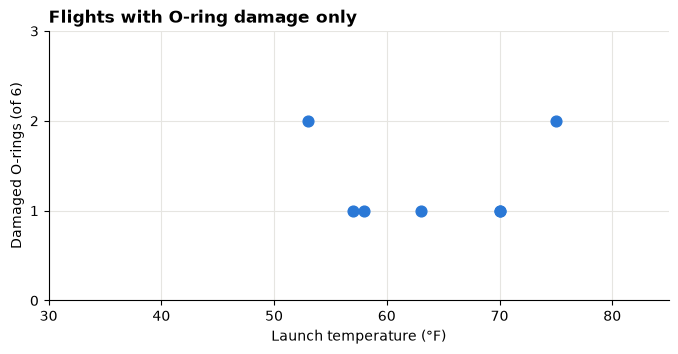

In [5]:
damaged = challenger[challenger["damaged_orings"] > 0]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(damaged["temp_f"], damaged["damaged_orings"], s=60, color=BLUE)
ax.set_xlim(30, 85)
ax.set_ylim(0, 3)
ax.set_yticks([0, 1, 2, 3])
ax.set_title("Flights with O-ring damage only")
ax.set_xlabel("Launch temperature (°F)")
ax.set_ylabel("Damaged O-rings (of 6)")
plt.show()

Damage appears at cool **and** warm temperatures. Looked at this way, temperature does not seem to matter much: two of the worst flights are far apart on the temperature axis.

### View 2: all 23 flights

> **Predict, then reveal**
>
> Now we add the flights with **no** damage. Where on the temperature axis do you expect them to sit?

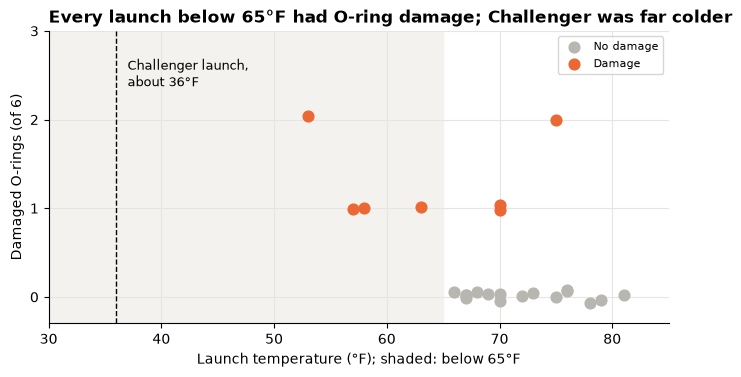

,flights,flights_with_damage,share_with_damage
band,,,
65°F and above,19,3,16%
below 65°F,4,4,100%


In [6]:
rng = np.random.default_rng(seed=14)
jitter = rng.uniform(-0.08, 0.08, len(challenger))     # separates flights with identical values
had_damage = challenger["damaged_orings"] > 0
cold = challenger["temp_f"] < 65

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(challenger.loc[~had_damage, "temp_f"], challenger.loc[~had_damage, "damaged_orings"] + jitter[~had_damage],
           s=60, color=GREY, label="No damage")
ax.scatter(challenger.loc[had_damage, "temp_f"], challenger.loc[had_damage, "damaged_orings"] + jitter[had_damage],
           s=60, color=ORANGE, label="Damage")
ax.axvline(CHALLENGER_TEMP_F, color="black", linestyle="--", linewidth=1)
ax.text(CHALLENGER_TEMP_F + 1, 2.7, "Challenger launch,\nabout 36°F", fontsize=9, va="top")
ax.axvspan(30, 65, color="#f3f2ef", zorder=0)
ax.set_xlim(30, 85)
ax.set_ylim(-0.3, 3)
ax.set_yticks([0, 1, 2, 3])
all_cold_damaged = bool(had_damage[cold].all())
ax.set_title("Every launch below 65°F had O-ring damage; Challenger was far colder"
             if all_cold_damaged else "O-ring damage against launch temperature, all flights")
ax.set_xlabel("Launch temperature (°F); shaded: below 65°F")
ax.set_ylabel("Damaged O-rings (of 6)")
ax.legend(fontsize=8, loc="upper right")
plt.show()

bands = challenger.assign(band=np.where(cold, "below 65°F", "65°F and above"), damage=had_damage)
bands.groupby("band").agg(flights=("flight", "count"), flights_with_damage=("damage", "sum"),
                          share_with_damage=("damage", "mean")).assign(
    share_with_damage=lambda t: t["share_with_damage"].map("{:.0%}".format))

Read the chart and table above together:

1. The flights with **no damage** were almost all **warm** launches. Leaving them out removed the evidence that warm launches were safe and cold ones were not.
2. In the shaded band below 65°F, read the table: what share of flights had damage, compared with warmer launches?
3. The dashed line is far to the left of **every** earlier flight. Challenger launched well outside all experience, so no chart of earlier flights could show what would happen at 36°F. That itself is the warning.

The lesson for analysts: **the rows you leave out can change the answer.** The zeros were the comparison group.

> **Two views of the lesson**
>
> Edward Tufte argued in *Visual Explanations* (1997) that the charts prepared before and after the accident failed to show the link between temperature and damage clearly, and that a simple scatter of all flights would have. Others, including some of the Thiokol engineers (Robison, Boisjoly, Hoeker and Young, 2002) and the sociologist Diane Vaughan (*The Challenger Launch Decision*, 1996), point out that the engineers **did** argue that cold was the danger, under time pressure, and that the decision was shaped by schedule, organisational culture and a habit of accepting earlier damage as normal. Both accounts lead to the same lesson for analysts: **when the stakes are high, show the full comparison so the risk is impossible to miss, and know that a good chart is necessary but not enough.**

> **Check your understanding 3**
>
> Write a message title for the "damaged flights only" chart that would have been **honest** about what it can and cannot show.

---

## Part 4: Decluttering a default chart, step by step

Default charts are made for exploring. To explain, we remove what does not carry information and direct the eye to what does. Tufte called the share of ink that shows data the **data-ink ratio**: raise it, without removing anything the reader needs (units, labels, context).

We use Profit by sub-category over 2023–2025. First the **before** (a typical default with extra decoration) and the **after**, side by side.

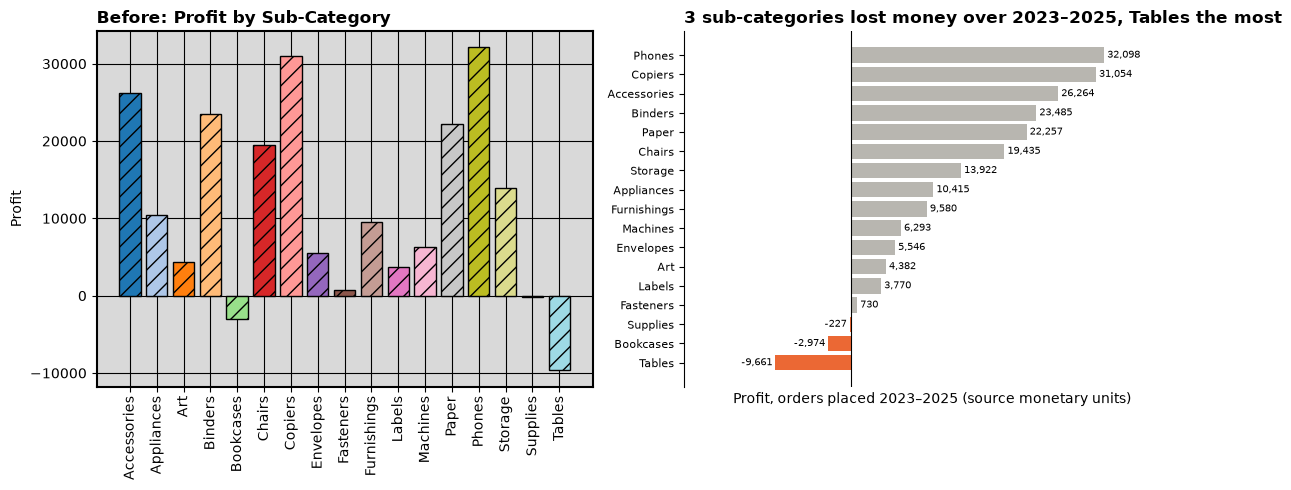

In [7]:
profit_sub = df.groupby("sub_category")["profit"].sum()


def profit_chart(ax, step):
    """Draw Profit by sub-category at a decluttering step from 0 (cluttered) to 4 (finished)."""
    values = profit_sub.sort_values() if step >= 2 else profit_sub
    if step == 0:
        colours = plt.cm.tab20(np.linspace(0, 1, len(values)))
        ax.bar(values.index, values, color=colours, edgecolor="black", hatch="//")
        ax.set_facecolor("#d9d9d9")
        ax.grid(True, axis="both", color="black", linewidth=0.8)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.5)
        ax.tick_params(axis="x", rotation=90)
        ax.set_title("Profit by Sub-Category")
        ax.set_ylabel("Profit")
        return
    if step == 1:
        ax.bar(values.index, values, color=BLUE)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="x", rotation=90, labelsize=8)
        ax.set_title("Step 1: remove decoration")
        ax.set_ylabel("Profit (source monetary units)")
        ax.yaxis.set_major_formatter(THOUSANDS)
        return
    colours = [ORANGE if v < 0 else GREY for v in values] if step >= 3 else BLUE
    ax.barh(values.index, values, color=colours)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(False)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("Profit, orders placed 2023–2025 (source monetary units)")
    ax.xaxis.set_major_formatter(THOUSANDS)
    if step >= 3:
        for i, v in enumerate(values):
            ax.text(v, i, f" {v:,.0f} " if v >= 0 else f"{v:,.0f} ", va="center",
                    ha="left" if v >= 0 else "right", fontsize=7)
        ax.set_xlim(values.min() * 2.2, values.max() * 1.3)
        ax.set_xticks([])
        ax.spines["bottom"].set_visible(False)
    if step == 2:
        ax.set_title("Step 2: sort, and turn horizontal")
    elif step == 3:
        ax.set_title("Step 3: one highlight colour, direct labels")
    else:
        losers = values[values < 0]
        ax.set_title(f"{len(losers)} sub-categories lost money over 2023–2025, {losers.idxmin()} the most")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
profit_chart(ax1, 0)
profit_chart(ax2, 4)
ax1.set_title("Before: Profit by Sub-Category")
fig.tight_layout()
plt.show()

> **Predict, then reveal**
>
> Look at the **before** chart for ten seconds, then look away. Which sub-categories lost money? Now do the same with the **after** chart. Which was faster, and why?

The steps in between, drawn one at a time:

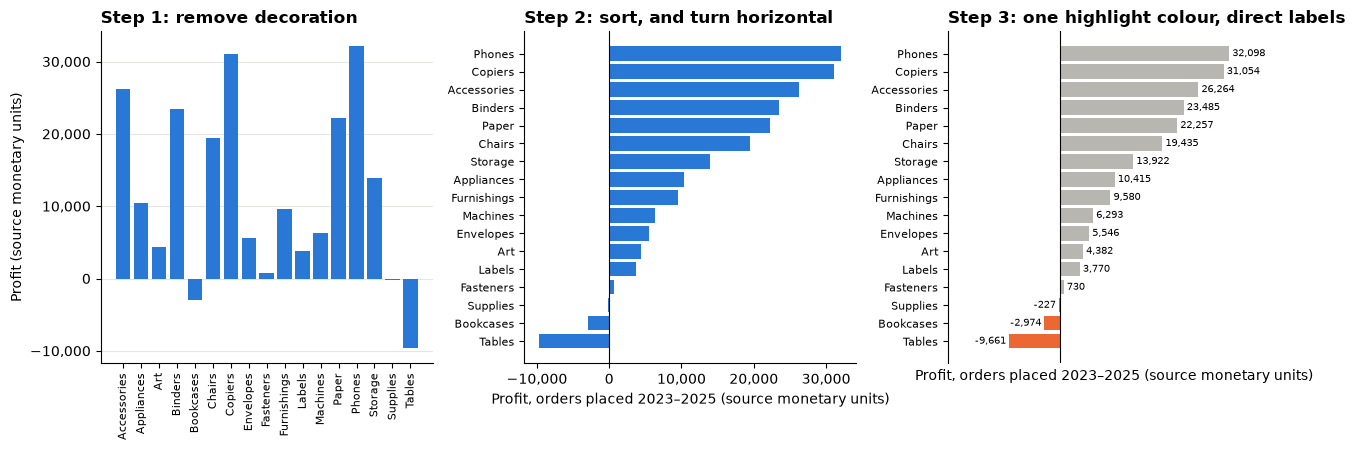

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, step in zip(axes, [1, 2, 3]):
    profit_chart(ax, step)
fig.tight_layout()
plt.show()

| Step | What changed | Why |
|---|---|---|
| 1 | Removed background shading, borders, hatching and rainbow colours | None of them carries data; they compete with the bars |
| 2 | Sorted the bars and turned them horizontal | The ranking is instant, and long labels are readable |
| 3 | Grey for context, **one** colour for the bars that matter; values on the bars | The eye goes straight to the losses; no need to read the axis |
| 4 | A **message title**, with the unit kept in the axis label | The reader knows what to notice and how it is measured |

### Honest axes

Removing clutter must never remove honesty. The most common distortion is a **truncated axis** on a bar chart: the length of a bar is the number, so the bar must start at zero.

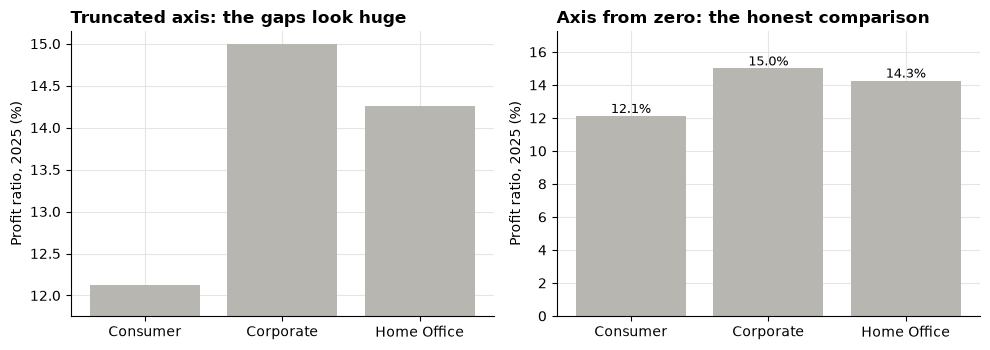

In [9]:
d25 = df[df["year"] == 2025]
profit_ratio = (d25.groupby("segment")["profit"].sum() / d25.groupby("segment")["sales"].sum()) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), sharex=False)
ax1.bar(profit_ratio.index, profit_ratio, color=GREY)
ax1.set_ylim(profit_ratio.min() * 0.97, profit_ratio.max() * 1.01)
ax1.set_title("Truncated axis: the gaps look huge")
ax1.set_ylabel("Profit ratio, 2025 (%)")
ax2.bar(profit_ratio.index, profit_ratio, color=GREY)
ax2.set_ylim(0, profit_ratio.max() * 1.15)
for i, v in enumerate(profit_ratio):
    ax2.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
ax2.set_title("Axis from zero: the honest comparison")
ax2.set_ylabel("Profit ratio, 2025 (%)")
fig.tight_layout()
plt.show()

The two charts above draw identical numbers. On the left, a difference of a few percentage points looks like one segment earns a fraction of another. Rules:

- **Bars and areas start at zero.** Their length or area is the value.
- **Lines may zoom in** (the axis need not start at zero) when the change over time is the point, as long as the axis is labelled.
- Use the **same scale** for panels the reader will compare.

> **Check your understanding 4**
>
> A colleague says "I removed the y-axis to declutter, and the bars are labelled, so it is fine." When is that acceptable, and what must still be true about the bars?

---

## Part 5: Dashboard design principles

A **dashboard** is a small set of views on one page that answers a recurring question. In Python we build it as one figure with several panels; in Tableau (later in the course) the same principles apply.

| Principle | What it means in practice |
|---|---|
| **Start from the decision** | A dashboard answers one question for one audience. If it answers everything, it answers nothing |
| **Layout hierarchy** | Readers start at the **top left**. Put the headline numbers and the main message there; supporting detail below and to the right |
| **3–5 views at most** | Each view earns its place by answering part of the question. More views means less attention for each |
| **Consistent colours per entity** | If 2025 is blue in one panel, it is blue in all of them. If orange means "needs attention", use it for nothing else |
| **KPI tiles** | A few headline numbers, each with a comparison (vs last year, vs target) so the reader knows whether it is good |
| **Annotations** | A short note on the chart where something happened beats a paragraph underneath |
| **Scope and source note** | Period, units, filters, data source, known limits: small, but always on the page |
| **Filters** | One control that changes every view (in Python: a function argument; in Tableau: a filter) |
| **Accessibility** | Colour-blind-safe colours, enough contrast, and **never colour alone**: add labels, positions or text |

### Accessibility in one minute

About one in twelve men has some colour-vision deficiency, most often difficulty telling red from green. This course uses blue, orange and aqua, which stay distinguishable for most colour-vision types, with grey for context. Even so, every highlighted bar above also has a **label** or a **position** that carries the same meaning, so the chart works in black and white.

> **Check your understanding 5**
>
> A dashboard shows six KPI tiles and nine charts, coloured red for "below target" and green for "above target". Name three changes you would make.

---

## Part 6: Worked case: a decision dashboard for the commercial lead

> *Commercial lead: "We are planning next year. Show me on one page how 2025 went, which segments are growing, and whether anything should worry us before we expand."*

The decision is **where to focus next year** and **what to check before expanding**. We plan the page before writing code:

| Position | View | Question it answers |
|---|---|---|
| Top row | Four KPI tiles | How big was 2025, and better or worse than 2024? |
| Middle, full width | Monthly Sales, 2025 against 2024 | Was growth steady through the year, or one lucky month? |
| Bottom left | Sales by segment, 2024 and 2025 | Which segments drove the growth? |
| Bottom right | Share of orders on the returns list, by region | Is anything worrying? |
| Bottom edge | Scope and source note | What does this cover, and what can it not show? |

Step 1 calculates every number the page needs. Growth uses whole years, so the season cancels out (Session 7). Shares are ratios of sums, never means of rates (Session 5).

In [10]:
d24, d25 = df[df["year"] == 2024], df[df["year"] == 2025]


def listed_share(data):
    """Share of distinct orders that appear on the returns list (ratio of sums)."""
    return data.loc[data["returned_order_flag"] == 1, "order_id"].nunique() / data["order_id"].nunique()


kpi = {
    "sales_2025": d25["sales"].sum(),
    "sales_growth": d25["sales"].sum() / d24["sales"].sum() - 1,
    "profit_ratio_2025": d25["profit"].sum() / d25["sales"].sum(),
    "profit_ratio_2024": d24["profit"].sum() / d24["sales"].sum(),
    "orders_2025": d25["order_id"].nunique(),
    "orders_growth": d25["order_id"].nunique() / d24["order_id"].nunique() - 1,
    "listed_2025": listed_share(d25),
}

segments = pd.DataFrame({"2024": d24.groupby("segment")["sales"].sum(),
                         "2025": d25.groupby("segment")["sales"].sum()})
segments["growth"] = segments["2025"] / segments["2024"] - 1
segments = segments.sort_values("2025")

two_years = df[df["year"].isin([2024, 2025])].assign(month=lambda t: t["order_date"].dt.month)
by_month = two_years.pivot_table(index="month", columns="year", values="sales", aggfunc="sum")

region_returns = pd.DataFrame({
    "orders": d25.groupby("region")["order_id"].nunique(),
    "listed": d25[d25["returned_order_flag"] == 1].groupby("region")["order_id"].nunique(),
}).fillna(0).astype(int)
region_returns["share"] = region_returns["listed"] / region_returns["orders"]
region_returns = region_returns.sort_values("share")

pd.Series({
    "Sales, 2025": f"{kpi['sales_2025']:,.0f}",
    "Sales growth vs 2024": f"{kpi['sales_growth']:+.1%}",
    "Orders, 2025": f"{kpi['orders_2025']:,}",
    "Order growth vs 2024": f"{kpi['orders_growth']:+.1%}",
    "Profit ratio, 2025 (2024)": f"{kpi['profit_ratio_2025']:.1%} ({kpi['profit_ratio_2024']:.1%})",
    "Orders on returns list, 2025": f"{kpi['listed_2025']:.1%}",
}).to_frame("value")

,value
"Sales, 2025","613,934"
Sales growth vs 2024,+29.8%
"Orders, 2025","1,340"
Order growth vs 2024,+27.3%
"Profit ratio, 2025 (2024)",13.5% (13.1%)
"Orders on returns list, 2025",5.7%


Step 2 draws the page. `fig.add_gridspec` divides the figure into a grid of rows and columns; each panel takes one or more cells, so the KPI row, the wide trend and the two bottom charts can have different sizes. Every title is built from the numbers, so it stays true if the data change.

> **Predict, then reveal**
>
> From the KPI table above, write the headline you expect at the top of the dashboard before you run the cell.

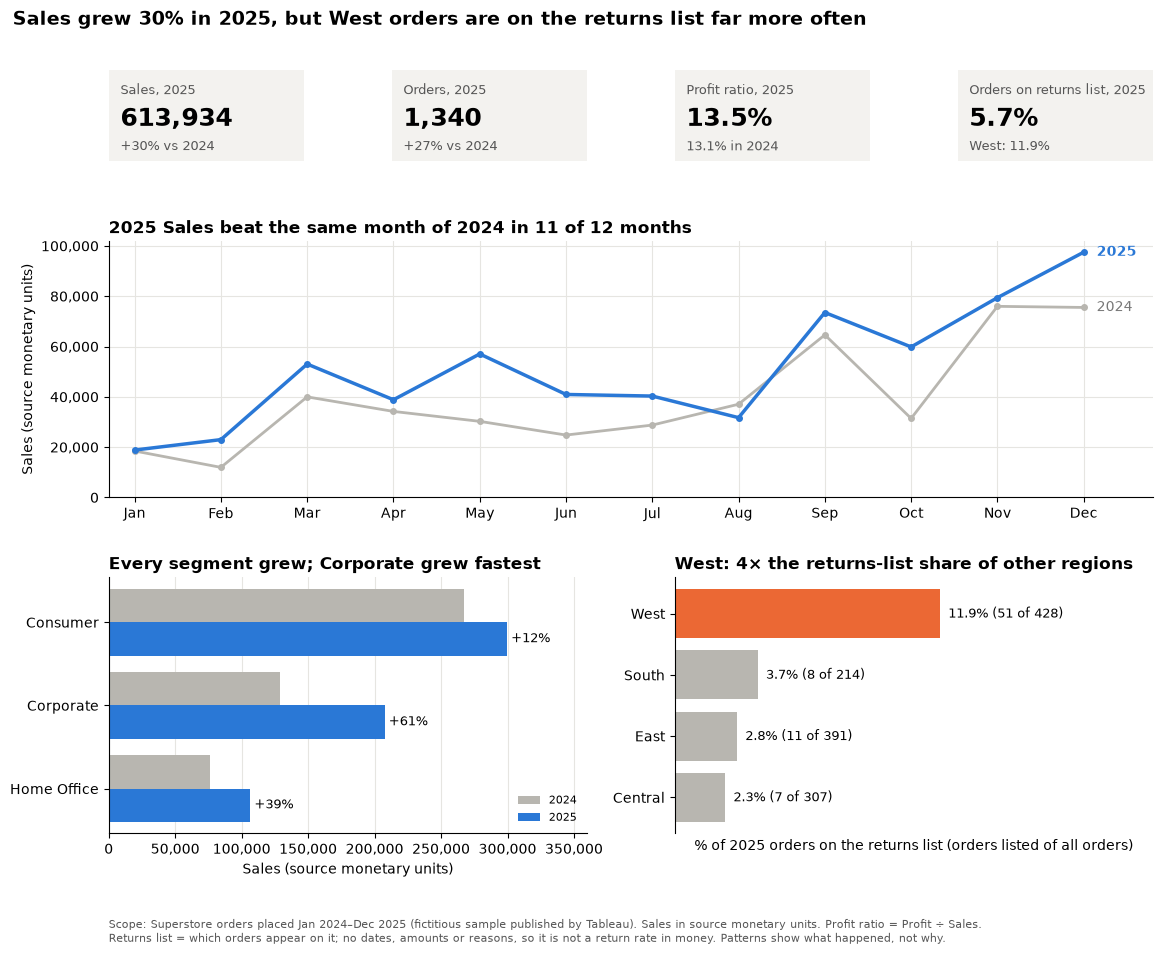

In [11]:
def kpi_tile(ax, label, value, note):
    """A text-only KPI tile: label, big number, comparison."""
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#f3f2ef", zorder=0))
    ax.text(0.06, 0.78, label, transform=ax.transAxes, fontsize=9, color="#555555", va="center")
    ax.text(0.06, 0.46, value, transform=ax.transAxes, fontsize=18, fontweight="bold", va="center")
    ax.text(0.06, 0.16, note, transform=ax.transAxes, fontsize=9, color="#555555", va="center")


top_region = region_returns.index[-1]
others = region_returns.drop(top_region)
others_share = others["listed"].sum() / others["orders"].sum()
all_grew = bool((segments["growth"] > 0).all())
months_above = int((by_month[2025] > by_month[2024]).sum())

fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(4, 4, height_ratios=[0.75, 2.1, 2.1, 0.3], hspace=0.5, wspace=0.45)

# Row 1: KPI tiles
kpi_tile(fig.add_subplot(gs[0, 0]), "Sales, 2025", f"{kpi['sales_2025']:,.0f}", f"{kpi['sales_growth']:+.0%} vs 2024")
kpi_tile(fig.add_subplot(gs[0, 1]), "Orders, 2025", f"{kpi['orders_2025']:,}", f"{kpi['orders_growth']:+.0%} vs 2024")
kpi_tile(fig.add_subplot(gs[0, 2]), "Profit ratio, 2025", f"{kpi['profit_ratio_2025']:.1%}",
         f"{kpi['profit_ratio_2024']:.1%} in 2024")
kpi_tile(fig.add_subplot(gs[0, 3]), "Orders on returns list, 2025", f"{kpi['listed_2025']:.1%}",
         f"{top_region}: {region_returns.loc[top_region, 'share']:.1%}")

# Row 2: monthly trend, 2025 against 2024
ax = fig.add_subplot(gs[1, :])
ax.plot(by_month.index, by_month[2024], color=GREY, linewidth=2, marker="o", markersize=4)
ax.plot(by_month.index, by_month[2025], color=BLUE, linewidth=2.5, marker="o", markersize=4)
ax.text(12.15, by_month.loc[12, 2025], "2025", color=BLUE, va="center", fontweight="bold")
ax.text(12.15, by_month.loc[12, 2024], "2024", color="#777777", va="center")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.7, 12.8)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_title(f"2025 Sales beat the same month of 2024 in {months_above} of 12 months")
ax.set_ylabel("Sales (source monetary units)")

# Row 3 left: segments, 2024 (grey) and 2025 (blue)
ax = fig.add_subplot(gs[2, :2])
y = np.arange(len(segments))
ax.barh(y + 0.2, segments["2024"], height=0.4, color=GREY, label="2024")
ax.barh(y - 0.2, segments["2025"], height=0.4, color=BLUE, label="2025")
for i, (value, growth) in enumerate(zip(segments["2025"], segments["growth"])):
    ax.text(value, i - 0.2, f" {growth:+.0%}", va="center", fontsize=9)
ax.set_yticks(y, segments.index)
ax.set_xlim(0, segments["2025"].max() * 1.2)
ax.xaxis.set_major_formatter(THOUSANDS)
ax.grid(axis="y", visible=False)
ax.set_title(("Every segment grew; " if all_grew else "") + f"{segments['growth'].idxmax()} grew fastest")
ax.set_xlabel("Sales (source monetary units)")
ax.legend(fontsize=8, loc="lower right", frameon=False)

# Row 3 right: returns-list share by region, one alert colour
ax = fig.add_subplot(gs[2, 2:])
ax.barh(region_returns.index, region_returns["share"] * 100,
        color=[ORANGE if r == top_region else GREY for r in region_returns.index])
for i, (share, listed, orders) in enumerate(zip(region_returns["share"], region_returns["listed"], region_returns["orders"])):
    ax.text(share * 100, i, f"  {share:.1%} ({listed} of {orders})", va="center", fontsize=9)
ax.set_xlim(0, region_returns["share"].max() * 100 * 1.8)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.set_title(f"{top_region}: {region_returns.loc[top_region, 'share'] / others_share:.0f}× the returns-list share of other regions")
ax.set_xlabel("% of 2025 orders on the returns list (orders listed of all orders)")

# Row 4: scope note
note = fig.add_subplot(gs[3, :])
note.axis("off")
note.text(0, 0.5, "Scope: Superstore orders placed Jan 2024–Dec 2025 (fictitious sample published by Tableau). "
          "Sales in source monetary units. Profit ratio = Profit ÷ Sales.\nReturns list = which orders appear on it; "
          "no dates, amounts or reasons, so it is not a return rate in money. Patterns show what happened, not why.",
          fontsize=8, color="#555555", va="center", transform=note.transAxes)

headline = f"Sales grew {kpi['sales_growth']:.0%} in 2025, but {top_region} orders are on the returns list far more often"
fig.suptitle(headline, x=0.02, y=0.96, ha="left", fontsize=14, fontweight="bold")
fig.subplots_adjust(left=0.1, right=0.97, top=0.9, bottom=0.02)
plt.show()

Check the dashboard above against the principles:

1. **Hierarchy:** the headline and the four tiles answer "how did 2025 go?" before the reader looks at any chart.
2. **Views:** three charts, each answering one part of the question.
3. **Colour:** grey always means "for comparison" (2024, other regions); blue always means 2025; orange appears once, for the one thing that needs attention.
4. **Not colour alone:** years are labelled at the end of the lines and in a legend; every bar has its number written on it.
5. **Scope note:** period, units, data source and the main limit of the returns list are on the page.

> **Check your understanding 6**
>
> The commercial lead asks for "the same page, but for the Central region only". Which titles on this page would you need to re-check, and why is building the page as code helpful here?

---

## Part 7: Writing for executives

Executives often read only the first lines. A **one-page brief** puts the answer first and the working last:

| Order | Part | Length |
|---|---|---|
| 1 | **Recommendation**: what to do, by when | One or two sentences |
| 2 | **Three evidence points**, each with one number and its comparison | One sentence each |
| 3 | **Risks and limits**: what the data cannot show, what could change the answer | Two or three sentences |
| 4 | **Next step**: the decision or check you need, and who does it | One sentence |

Rules: every number has a comparison and a unit; no jargon (say "share of orders on the returns list", not "RL ratio"); association is not causation; say what you do **not** know.

The draft below fills the structure from the numbers calculated above. No number is typed by hand.

In [12]:
best_segment = segments["growth"].idxmax()
print("RECOMMENDATION")
print(f"Plan for continued growth in 2026, but before expanding in the {top_region} region, investigate why its "
      f"orders appear on the returns list so often, starting with the products listed most.")
print()
print("EVIDENCE")
print(f"1. Sales reached {kpi['sales_2025']:,.0f} in 2025, {kpi['sales_growth']:+.0%} on 2024, and were higher than "
      f"the same month a year earlier in {months_above} of 12 months.")
print(f"2. {'Every segment grew; ' if all_grew else ''}{best_segment} grew fastest "
      f"({segments.loc[best_segment, 'growth']:+.0%}), and the profit ratio moved from "
      f"{kpi['profit_ratio_2024']:.1%} to {kpi['profit_ratio_2025']:.1%}.")
print(f"3. {region_returns.loc[top_region, 'share']:.1%} of {top_region} orders in 2025 are on the returns list, "
      f"against {others_share:.1%} in the other regions combined.")
print()
print("RISKS AND LIMITS")
print("The returns list shows which orders were listed, not when, how much was refunded or why; "
      "the gap may reflect how returns are recorded in that region rather than customer behaviour. "
      "The data are a fictitious sample, and these patterns describe what happened, not what caused it.")
print()
print("NEXT STEP")
print(f"Ask the {top_region} regional manager for return reasons and refund amounts for 2025, and review them "
      "with us before the expansion budget is approved.")

RECOMMENDATION
Plan for continued growth in 2026, but before expanding in the West region, investigate why its orders appear on the returns list so often, starting with the products listed most.

EVIDENCE
1. Sales reached 613,934 in 2025, +30% on 2024, and were higher than the same month a year earlier in 11 of 12 months.
2. Every segment grew; Corporate grew fastest (+61%), and the profit ratio moved from 13.1% to 13.5%.
3. 11.9% of West orders in 2025 are on the returns list, against 2.9% in the other regions combined.

RISKS AND LIMITS
The returns list shows which orders were listed, not when, how much was refunded or why; the gap may reflect how returns are recorded in that region rather than customer behaviour. The data are a fictitious sample, and these patterns describe what happened, not what caused it.

NEXT STEP
Ask the West regional manager for return reasons and refund amounts for 2025, and review them with us before the expansion budget is approved.


Notice what the brief does **not** do: it does not claim the region's customers are worse, or that returns cost a particular amount. The data cannot show either.

> **Check your understanding 7**
>
> Rewrite evidence point 3 as a sentence a busy executive would read in five seconds. Then write one alternative explanation for the gap that the next step would test.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| Who is this for, and what will they decide? | Audience and decision, written down first | Showing everything you explored |
| What is the one message? | A big-idea sentence with a point of view and stakes | A topic ("Sales overview") instead of a message |
| How does the story flow? | Situation → complication → resolution | Burying the recommendation at the end |
| What should the reader notice? | Message titles, one highlight colour, annotations | Descriptive titles, rainbow colours |
| Is the chart honest? | Bars from zero, full comparison group, same scales | Truncated axes; leaving out the "no damage" flights |
| Is the dashboard readable? | Top-left hierarchy, 3–5 views, consistent colours, scope note | Ten charts, colours that change meaning, no scope |
| Can everyone read it? | Colour-blind-safe palette and labels | Meaning carried by colour alone |
| Will executives act on it? | Recommendation first, three evidence points, limits, next step | Method first, answer last |

---

## Quiz

Answer these at the start of the next lecture, on the **capstone**: combining evidence from several business areas into one recommendation. Use common sense. Write short answers.

1. You have monthly retail Sales and monthly HR turnover. Why could joining them on month and finding that they move together **not** show that turnover affects Sales?
2. Two datasets cover different periods (one 2023–2025, one 2025 only). How would you compare them fairly?
3. For each number in a final report, list four things you would record so a reviewer could check it.
4. One dataset suggests a problem that another dataset seems to contradict. What do you do before writing your recommendation?
5. What would you put in a short "validation pack" to convince a sceptical reviewer that your numbers are right?
6. You can recommend only one of two actions: one has strong evidence and a small benefit, the other weak evidence and a large benefit. How would you present the trade-off?

---

## Lab briefing

In the **Lab** you:

1. Declutter a deliberately cluttered chart, step by step.
2. Rewrite three descriptive titles as message titles.
3. Build a three-panel retail dashboard with a scope note.
4. Choose one case (retail or marketing), build a decision dashboard from a skeleton function, and write a big idea and a five-sentence executive brief.
5. Check your dashboard for accessibility.
6. Challenge: find and fix five problems in a misleading dashboard, then outline a three-slide story.

Open the [Session 14 lab](14_dashboards_storytelling_lab.md).